[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/steeve-g/notebooks/12_retina_eigenvectors_of_G_per_scale.ipynb)

# Retina: leading eigenvectors of G(x) at each noise scale

* **Author**: laquitainesteeve@gmail.com

* **Goal**: Task 1 of the note *Scale-resolved decomposition of G(x)* for the retina: split G(x) into its contributions from each noise scale, $M_t(x)$, and plot the leading eigenvectors of $M_t(x)$ against the noise scale, for the mosaics of two retinal cell types, W3 and transient OFF alpha (tOFFalpha), as notebook 7 does for V1 and V4.

* **Requirements**: the `openretina` package with Baptiste Lorenzi's retina models (the private repository `open-retina-multigeom`), the retina checkpoints (downloaded below), TinyImageNet, and a GPU.

* **Time**: about 12 min on a GPU, or seconds when the stored results are reloaded.

## 1. Setup

### 1.1. Install package

Install the version of `multigeom` this notebook needs, the `g-per-scale` branch on GitHub, and, on Google Colab, `openretina` from the private repository `open-retina-multigeom` (with a GitHub token stored in Colab's secrets as `GH_TOKEN`). Elsewhere, `multigeom` is installed only if the installed one lacks its functions, and `openretina` as the README of `tests/fixtures/retina/` says.

time: <1 sec

In [1]:
%%time

# the multigeom this notebook needs: the g-per-scale branch on GitHub, until it is
# released (without its dependencies: Colab already has torch, numpy, scipy and
# matplotlib, and reinstalling torch is slow and can break the GPU runtime)
import os
import sys

BRANCH = "git+https://github.com/multigeom/multigeom.git@g-per-scale"

# on Google Colab: install the latest commit of that branch (forced: pip skips a
# branch it installed before, even if the branch has changed since), and the
# diffusion models' library
if "google.colab" in sys.modules:
    %pip install -q --no-deps --force-reinstall {BRANCH}
    %pip install -q "diffusers>=0.30,<0.38"

    # an older multigeom imported earlier in this session stays in memory: restart
    # the session so that the next cells import the new one (then run them from the
    # next cell on)
    # open-retina with Baptiste Lorenzi's retina models: the private repository
    # open-retina-multigeom, with a GitHub token in Colab's secrets (GH_TOKEN)
    from google.colab import userdata

    TOKEN = userdata.get("GH_TOKEN")
    RETINA = "github.com/steevelaquitaine/open-retina-multigeom.git"
    %pip install -q --no-deps "git+https://{TOKEN}@{RETINA}"
    DEPENDENCIES = (
        "jaxtyping hydra-core lightning tenacity opencv-python-headless seaborn"
    )
    %pip install -q {DEPENDENCIES} moviepy

    if "multigeom" in sys.modules:
        print("restarting the session to load the new multigeom: run the next cells")
        os.kill(os.getpid(), 9)

# on your own machine: install that branch only if the installed multigeom lacks its
# functions (this replaces an editable install; restart the kernel afterwards)
else:
    import multigeom

    if not hasattr(multigeom.analysis, "compute_bootstrap"):
        %pip install -q --no-deps {BRANCH}
        print("installed multigeom from the g-per-scale branch: restart the kernel")

CPU times: user 3.11 s, sys: 92.7 ms, total: 3.21 s
Wall time: 617 ms


### 1.2. Imports and parameters

Work from the repository root, import the packages, and set the parameters: the two cell types and their models, the test images, the number of samples per noise scale, and where the results and figures go.

<details><summary>Details</summary>

* `load_retina` loads, for one cell, the mosaic of its Lorenzi model (its readout slid over a hexagonal lattice 200 µm apart on a 120 x 120 image), the conditional diffusion model of that mosaic, and the Poisson noise of its responses; `load_retina_test_images` loads the 6 test images of Baptiste's figures.
* The models are named as those of V1 and V4: `runs/encoders/lorenzi/<area>/best_model.pt` and `runs/diffusion/lorenzi/<area>/final_model.pt`, the area being the cell type and the cell.

</details>

time: 1 sec

In [2]:
%%time

import copy
import os
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from huggingface_hub import snapshot_download

# move to the repository root (the folder containing environment.yml): data/, runs/
# and assets/ are read and written from there
root = Path.cwd().resolve()
while not (root / "environment.yml").exists() and root != root.parent:
    root = root.parent

if (root / "environment.yml").exists():
    os.chdir(root)

print("repo root:", root)

from multigeom.config import load_config
from multigeom.datasets import download_tinyimagenet
from multigeom.encoders.retina import load_retina, load_retina_test_images
from multigeom.pipeline.per_scale import compute_per_scale
from multigeom.plotting import plot_per_scale
from multigeom.utils import get_device, load_intermediate, save_intermediate

# the parameters of this notebook
PARAMS = {
    # the two cell types and the area of their models (runs/<stage>/lorenzi/<area>/):
    # W3, small with a strong surround, and tOFFalpha, large with a weak surround
    "cell_types": {"W3": "retina-W3_176-exp7", "tOFFalpha": "retina-tOFFalpha_17-exp5"},
    # the test images of Baptiste's figures: TinyImageNet training images 50,000 to
    # 50,005 in open-retina's shuffled order, and the images the models were fitted to
    "n_images": 6,
    "frames": "data/tiny-imagenet-200/train",
    "normalizer": "data/02_intermediate/retina/normalizer.pt",
    # Monte-Carlo samples per noise scale (Baptiste's G(x) uses 150)
    "n_samples": 150,
    # leading eigenvectors kept and drawn at each noise scale
    "n_eigvecs": 4,
    # where the computed results are stored, so that a new run reloads them in seconds
    # instead of recomputing them (True: recompute and overwrite them)
    "intermediate_dir": "data/02_intermediate/12_retina_eigenvectors_of_G_per_scale",
    "recompute": False,
    # where the figures are saved (one per image), their resolution in the file and
    # on screen, and the images whose figures stay in the notebook (each is about 1 MB)
    "figure_dir": "assets/figures/retina/v1/task1",
    "file_dpi": 200,
    "screen_dpi": 100,
    "show": ["img2"],
}

# the estimator config (packaged with multigeom)
est_cfg = load_config("estimator")

# compute device
device = get_device(None)
print("device:", device)

repo root: /home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials


device: cuda
CPU times: user 647 ms, sys: 106 ms, total: 753 ms
Wall time: 763 ms


## 2. Download the retina models

The checkpoints of the two cells (their Lorenzi models and the diffusion models of their mosaics) are on Hugging Face, with those of V1 and V4; only the retina ones are downloaded.

time: <1 sec

In [3]:
%%time

# download the retina checkpoints into runs/ (files that are already there are kept)
snapshot_download(
    repo_id="steevelaquitaine/multigeom", local_dir="runs", allow_patterns="*/lorenzi/*"
)

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

CPU times: user 133 ms, sys: 36.6 ms, total: 169 ms
Wall time: 543 ms


'/home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials/runs'

## 3. Download datasets

TinyImageNet gives the test images, and the images the image units were fitted to (240 MB the first time).

time: <1 sec

In [4]:
%%time

# TinyImageNet (nothing if already there)
download_tinyimagenet()

CPU times: user 141 μs, sys: 10 μs, total: 151 μs
Wall time: 118 μs


PosixPath('/home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials/data/tiny-imagenet-200')

## 4. Compute $M_t(x)$ at each noise scale

As in notebook 7: G(x) adds up, over the noise scales t, the information that the responses carry about the image, $G(x) = \int M_t(x)\, d\log t$. We estimate $M_t(x)$ at each of the 24 noise scales of the paper's grid, for each test image and the mosaics of the two cell types, and keep its leading 4 eigenvectors and eigenvalues.

<details><summary>Details</summary>

* **Poisson noise.** The responses of a retinal cell are spike counts: given the image, the counts $n \sim \mathrm{Poisson}(g\,\lambda(x))$, with $\lambda$ the rate of the encoder and $g$ the exposure of the cell (the window over its Fano factor), and the response is $n / g$. The diffusion models were trained with this noise, so the responses are drawn with it (`models.noise`), where notebook 7 adds Gaussian noise.
* **Images.** 120 x 120 pixels, one channel, scaled as the models were trained (about ±0.8).
* **Samples.** 150 per noise scale, as Baptiste's G(x) (`tests/test_retina.py` checks that our G(x) reproduces his figures).
* **Stored results.** They are saved in `data/02_intermediate/12_retina_eigenvectors_of_G_per_scale/` and reloaded by the next runs, unless `"recompute"` is True.

</details>

time: 10 min (computed), or seconds (reloaded)

In [5]:
%%time

# 1. estimator settings: those of the paper, with n_samples Monte-Carlo samples per
# noise scale and the n_eigvecs leading eigenpairs kept at each scale
cfg = copy.deepcopy(est_cfg)
cfg.monte_carlo.n_samples = PARAMS["n_samples"]
cfg.top_k = PARAMS["n_eigvecs"]
frames = Path(PARAMS["frames"])

# 2. the results of every cell type, reloaded if stored, else computed and stored;
# results[cell_type][name] holds tau = log t, the eigenvalues and the eigenvectors
results_file = Path(PARAMS["intermediate_dir"]) / "results.pt"
if results_file.exists() and not PARAMS["recompute"]:
    results, examples = load_intermediate(results_file)
else:
    results = {}
    for cell_type, area in PARAMS["cell_types"].items():
        # the cell's models, and the Poisson noise of its responses for the estimator
        models = load_retina(
            area, Path("runs"), frames, device, normalizer_cache=PARAMS["normalizer"]
        )
        cfg.monte_carlo.noise = models.noise

        # the test images, each with the seed of its Monte-Carlo draws
        images = load_retina_test_images(models, frames, n=PARAMS["n_images"])
        examples = {
            f"img{i}": (image[None], int(cfg.seed) + i)
            for i, image in enumerate(images)
        }

        # M_t(x) of every image
        results[cell_type] = compute_per_scale(
            examples, models.encoder, models.unet, models.alphas_cumprod, cfg, device
        )
        print(cell_type, "done:", len(results[cell_type]), "images")
    save_intermediate((results, examples), results_file)

/home/steeve/miniconda3/envs/tutorials-env/lib/python3.11/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'core' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['core'])`.
/home/steeve/miniconda3/envs/tutorials-env/lib/python3.11/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'readout' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['readout'])`.


W3 done: 6 images


tOFFalpha done: 6 images
CPU times: user 8min 10s, sys: 1min 9s, total: 9min 20s
Wall time: 9min 16s


## 5. Plot the leading eigenvectors at each noise scale

One figure per image, saved to `assets/figures/retina/v1/task1/eigenvectors_per_scale_<image>.png`; to keep the notebook small, it shows only those of the images in `PARAMS["show"]` (the bus). Each figure has the image (A), the leading 4 eigenvectors of $M_t(x)$ at each noise scale for W3 (B) and tOFFalpha (C), from the finest noise scale (left) to the coarsest (right), and their eigenvalues, each cell type over its largest leading eigenvalue (D).

<details><summary>Details</summary>

* Each eigenvector is drawn like those of notebook 7: red positive, blue negative, scaled to its own 99th percentile of |v|; its sign, arbitrary, agrees with the same eigenvector at the next coarser scale.
* No receptive-field outlines: the mosaics tile the whole image (each cell's window is about 330 µm across, the cells 200 µm apart).

</details>

time: 15 secs

6 figures saved in assets/figures/retina/v1/task1
CPU times: user 10.3 s, sys: 158 ms, total: 10.5 s
Wall time: 9.34 s


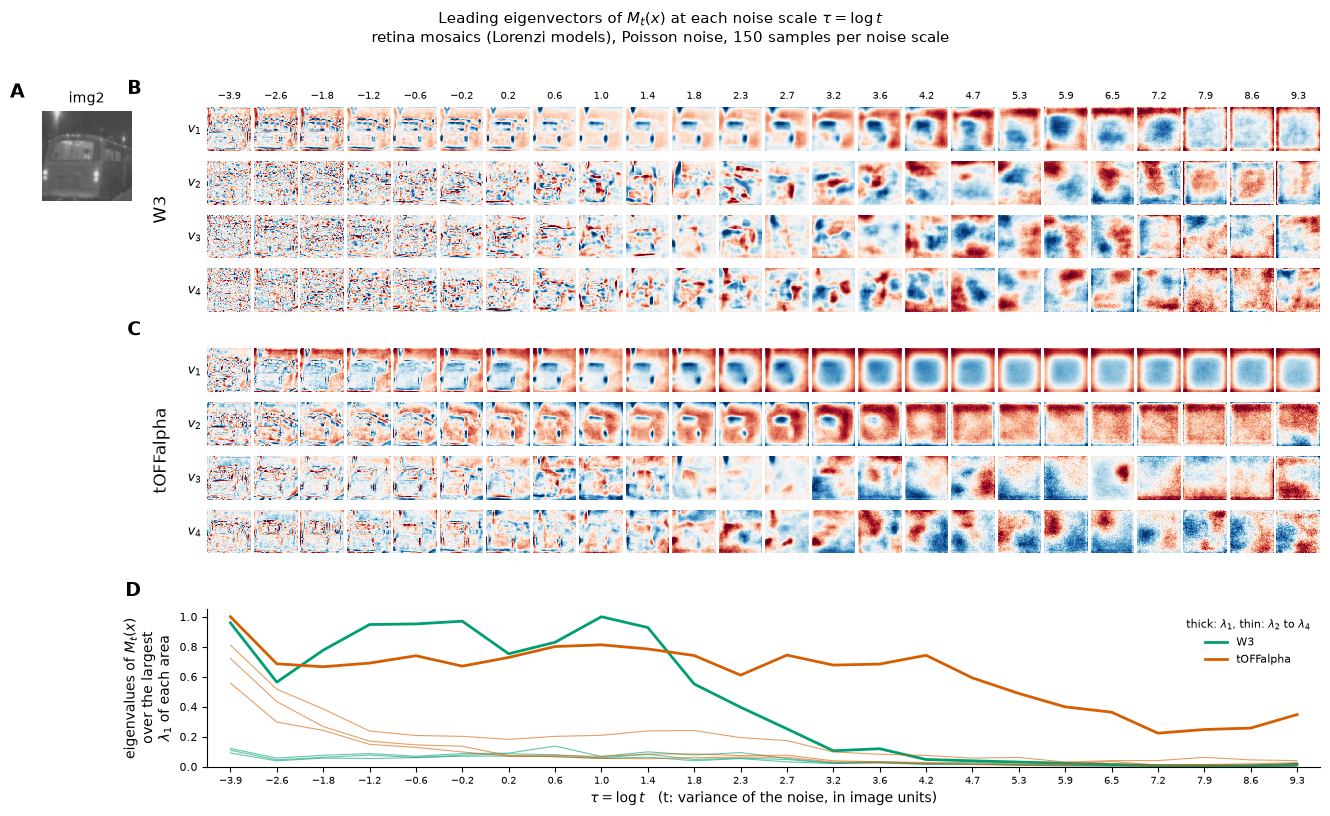

In [6]:
%%time

# 1. the folder of the figures, and the title of every figure
figure_dir = Path(PARAMS["figure_dir"])
figure_dir.mkdir(parents=True, exist_ok=True)
suptitle = (
    r"Leading eigenvectors of $M_t(x)$ at each noise scale $\tau = \log t$"
    f"\nretina mosaics (Lorenzi models), Poisson noise, {PARAMS['n_samples']}"
    " samples per noise scale"
)

# 2. one figure per image: draw it, keep the data it shows, and save it; only the
# figures of the images in PARAMS["show"] stay in the notebook
plotted = {}
for name, (image, _) in examples.items():
    records = {cell_type: results[cell_type][name] for cell_type in results}
    fig, plotted[name] = plot_per_scale(
        image.cpu(), records, PARAMS, name, suptitle, {}
    )
    fig.savefig(
        figure_dir / f"eigenvectors_per_scale_{name}.png",
        dpi=PARAMS["file_dpi"],
        bbox_inches="tight",
    )
    if name not in PARAMS["show"]:
        plt.close(fig)

# 3. where the figures are
print(len(plotted), "figures saved in", figure_dir)

## 6. Conclusion

* **What we computed.** $M_t(x)$ at the 24 noise scales of the paper's grid, for the 6 test images of Baptiste's figures and the mosaics of W3 cell 176-exp7 and tOFFalpha cell 17-exp5, with Poisson noise and 150 samples per scale: about 9 min on one GPU. The figures are in `assets/figures/retina/v1/task1/`.
* **Two cell types, two ranges of scales.** On the bus and the goose (panel D), the leading eigenvalue of W3 falls to almost zero by $\tau \approx 4$ to 6, while that of tOFFalpha keeps 10 to 35% of its peak at the coarsest scales. W3 carries its information at fine and middle scales, tOFFalpha also at coarse ones.
* **What the eigenvectors look like.** At fine scales both follow the image (the bus's outline and lights). At coarse scales, the leading eigenvector of tOFFalpha becomes the same smooth pattern on both images, a bright frame around a dark centre: the change of mean luminance over the field, as Baptiste found for the alpha cells. Those of W3 stay patchy.
* **Caveat.** Two cells and 6 images, and 150 samples per scale: the eigenvectors at fine scales change from one seed to the next (as in notebook 7).
* **Next steps.** Tasks 2 to 4 for the retina: the stimulus features (notebook 13), the envelope spectrum (14) and the coding spectrum of each cell type (15).